# Animation, Motion and Temporal Visualization — Demo Notebook
**UE24CS342AA9 · Unit 3 · PPT 5**

This notebook demonstrates every concept in the lecture on real data, and works through all six numericals from the slides in code.

### Datasets (Kaggle, public)
| Dataset | Used for | Link |
|---|---|---|
| **Metro Interstate Traffic Volume** (hourly I-94 traffic, Minneapolis–St Paul, 2012–2018, with weather and holidays) | temporal data, sampling, aggregation, filtering, events, encodings, transitions, animation vs small multiples | https://www.kaggle.com/datasets/anshtanwar/metro-interstate-traffic-volume |
| **Hurricanes and Typhoons, 1851–2014** (NOAA, 6-hourly storm positions, file `atlantic.csv`) | timelines, spatial animation, trajectories, space-time cube | https://www.kaggle.com/datasets/noaa/hurricane-database |

Particle animation (slide 19) uses analytic vector fields, including the one from Numerical 4.

| # | Section | Slides |
|---|---|---|
| 0 | Setup and data loading | – |
| 1 | Temporal data fundamentals: time as key vs value, continuous vs discrete, irregular sampling | 21–23 |
| 2 | Time-series visualization | 26 |
| 3 | Temporal encoding: position, angle, colour, connection | 25 |
| 4 | Temporal aggregation and moving averages (+ Numerical 5) | 27–28 |
| 5 | Temporal filtering and dynamic queries | 29 |
| 6 | Events over time | 24 |
| 7 | Timeline visualization | 30 |
| 8 | Temporal sampling, Nyquist and aliasing (+ Numerical 2) | 10–11 |
| 9 | Frame rate and animation timing, easing (+ Numericals 1 & 3) | 7–9, 14 |
| 10 | Motion as a visual variable | 6 |
| 11 | Animated transitions: jump cut vs smooth, staging | 12–13 |
| 12 | Change detection and change blindness | 15 |
| 13 | Animation for trends vs traces vs small multiples | 5, 16 |
| 14 | Animation for spatial data | 17 |
| 15 | Motion and trajectories, space-time cube | 18 |
| 16 | Particle animation, streamlines / pathlines / streaklines (+ Numerical 4) | 19–20 |
| 17 | Playback, scrubbing and temporal navigation | 31–32 |
| 18 | Animation vs static views vs small multiples (+ Numerical 6) | 33–36 |
| 19 | Cognitive issues and design guidelines | 37–38 |

> **Tip:** Plotly figures have ▶ Play buttons and sliders. Matplotlib animations appear as small players with play, pause and step controls.

## 0. Setup and data loading

In [1]:
%pip install -q kagglehub plotly

In [2]:
import os, glob, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.collections import LineCollection
import plotly.express as px, plotly.graph_objects as go
from IPython.display import HTML, display

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "animation.embed_limit": 60})
pd.set_option("display.width", 140)

def show_anim(anim):
    """Render a matplotlib animation as an interactive HTML player (works in Colab and Jupyter)."""
    anim._fig.set_dpi(72); html = HTML(anim.to_jshtml()); plt.close(anim._fig); return html

In [3]:
def kaggle_csv(slug, pattern, local_name):
    """Use a local copy if present, otherwise download the Kaggle dataset with kagglehub."""
    if os.path.exists(local_name):
        return local_name
    import kagglehub
    folder = kagglehub.dataset_download(slug)
    return sorted(glob.glob(os.path.join(folder, "**", pattern), recursive=True))[0]

TRAFFIC_CSV = kaggle_csv("anshtanwar/metro-interstate-traffic-volume", "*.csv", "Metro_Interstate_Traffic_Volume.csv")
HURR_CSV    = kaggle_csv("noaa/hurricane-database", "atlantic.csv", "atlantic.csv")
print(TRAFFIC_CSV, "|", HURR_CSV)

Using Colab cache for faster access to the 'metro-interstate-traffic-volume' dataset.


100%|██████████| 901k/901k [00:00<00:00, 103MB/s]

Extracting files...
/kaggle/input/metro-interstate-traffic-volume/Metro_Interstate_Traffic_Volume.csv | /root/.cache/kagglehub/datasets/noaa/hurricane-database/versions/1/atlantic.csv


In [4]:
def parse_time(s):
    """Parse the date_time column; different Kaggle copies use different formats."""
    for kw in [dict(format="%Y-%m-%d %H:%M:%S"), dict(format="%d-%m-%Y %H:%M"), dict(format="%d-%m-%Y %H:%M:%S"),
               dict(format="mixed", dayfirst=True)]:
        t = pd.to_datetime(s, errors="coerce", **kw)
        if t.notna().mean() > 0.99:
            return t
    raise ValueError("Could not parse date_time")

raw = pd.read_csv(TRAFFIC_CSV)
raw.columns = raw.columns.str.strip().str.lower()
raw["date_time"] = parse_time(raw["date_time"])
raw["holiday"] = raw["holiday"].fillna("None").astype(str).str.strip().replace({"": "None", "nan": "None"})
print("Raw rows:", len(raw), "| duplicate timestamps:", raw.date_time.duplicated().sum())

# One row per hour (duplicates come from several weather labels per hour)
tr = raw.drop_duplicates("date_time").sort_values("date_time").set_index("date_time")
tr["temp_c"] = tr["temp"].where(tr["temp"] > 200) - 273.15           # Kelvin → °C, drop 0 K sensor errors

# The holiday name is only on the midnight row of each holiday, so spread it to the whole day
hol = tr.loc[tr.holiday != "None", "holiday"]
hol_by_day = pd.Series(hol.values, index=hol.index.normalize()); hol_by_day = hol_by_day[~hol_by_day.index.duplicated()]
tr["holiday_day"] = tr.index.normalize().map(hol_by_day).fillna("None")
tr["hour"], tr["dow"], tr["month"], tr["year"] = tr.index.hour, tr.index.dayofweek, tr.index.month, tr.index.year
tr["weekend"] = tr["dow"] >= 5
DOW = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print(f"Clean hourly rows: {len(tr):,}  |  {tr.index.min()} → {tr.index.max()}")
tr.head()

Raw rows: 48204 | duplicate timestamps: 7629
Clean hourly rows: 40,575  |  2012-10-02 09:00:00 → 2018-09-30 23:00:00


,traffic_volume,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,temp_c,holiday_day,hour,dow,month,year,weekend
date_time,,,,,,,,,,,,,,,
2012-10-02 09:00:00,5545,None,288.28,0.0,0.0,40,Clouds,scattered clouds,15.13,None,9,1,10,2012,False
2012-10-02 10:00:00,4516,None,289.36,0.0,0.0,75,Clouds,broken clouds,16.21,None,10,1,10,2012,False
2012-10-02 11:00:00,4767,None,289.58,0.0,0.0,90,Clouds,overcast clouds,16.43,None,11,1,10,2012,False
2012-10-02 12:00:00,5026,None,290.13,0.0,0.0,90,Clouds,overcast clouds,16.98,None,12,1,10,2012,False
2012-10-02 13:00:00,4918,None,291.14,0.0,0.0,75,Clouds,broken clouds,17.99,None,13,1,10,2012,False


In [5]:
hu = pd.read_csv(HURR_CSV)
hu.columns = hu.columns.str.strip()
for c in ["ID", "Name", "Status", "Latitude", "Longitude"]:
    hu[c] = hu[c].astype(str).str.strip()
hu["time"] = pd.to_datetime(hu["Date"].astype(str) + hu["Time"].astype(int).astype(str).str.zfill(4), format="%Y%m%d%H%M")
def _coord(s):
    v = s.str[:-1].astype(float)
    return np.where(s.str[-1].isin(["S", "W"]), -v, v)
hu["lat"], hu["lon"] = _coord(hu["Latitude"]), _coord(hu["Longitude"])
hu["wind"] = hu["Maximum Wind"].where(hu["Maximum Wind"] >= 0)
hu["storm"] = hu["Name"].str.title() + " (" + hu["ID"] + ")"
hu["year"] = hu["time"].dt.year
print(f"{hu.ID.nunique():,} Atlantic storms, {len(hu):,} track points, {hu.year.min()}–{hu.year.max()}")
hu.head(3)

1,814 Atlantic storms, 49,105 track points, 1851–2015


,ID,Name,Date,Time,Event,Status,Latitude,Longitude,Maximum Wind,Minimum Pressure,...,High Wind NE,High Wind SE,High Wind SW,High Wind NW,time,lat,lon,wind,storm,year
0,AL011851,UNNAMED,18510625,0,,HU,28.0N,94.8W,80,-999,...,-999,-999,-999,-999,1851-06-25 00:00:00,28.0,-94.8,80.0,Unnamed (AL011851),1851
1,AL011851,UNNAMED,18510625,600,,HU,28.0N,95.4W,80,-999,...,-999,-999,-999,-999,1851-06-25 06:00:00,28.0,-95.4,80.0,Unnamed (AL011851),1851
2,AL011851,UNNAMED,18510625,1200,,HU,28.0N,96.0W,80,-999,...,-999,-999,-999,-999,1851-06-25 12:00:00,28.0,-96.0,80.0,Unnamed (AL011851),1851


## 1. Temporal data fundamentals  *(slides 21–23)*
### Time as a **key** vs time as a **value**
- **Time-dependent (time-varying):** in the traffic data, `traffic_volume = f(date_time)`. Time is the independent **key**, so this is a **time series**.
- **Temporal attribute but not time-varying:** each hurricane's **duration** is a temporal *value* describing the storm, like a race time. The storm ID is the key.

The dataset alone doesn't tell you which case you're in; you need to know what it describes.

In [6]:
durations = (hu.groupby("storm")["time"].agg(["min", "max"]).assign(duration_days=lambda d: (d["max"] - d["min"]).dt.total_seconds() / 86400))
print("Time as a VALUE → one duration per storm (key = storm):")
display(durations.sort_values("duration_days", ascending=False).head(5).round(2))
print("Time as a KEY → a time series of traffic volume:")
display(tr[["traffic_volume"]].head(5))

Time as a VALUE → one duration per storm (key = storm):


,min,max,duration_days
storm,,,
Unnamed (AL031899),1899-08-03 00:00:00,1899-09-04 18:00:00,32.75
Ginger (AL141971),1971-09-06 00:00:00,1971-10-05 06:00:00,29.25
Inga (AL201969),1969-09-20 12:00:00,1969-10-15 00:00:00,24.50
Nadine (AL142012),2012-09-10 12:00:00,2012-10-04 06:00:00,23.75
Unnamed (AL041926),1926-09-01 00:00:00,1926-09-24 12:00:00,23.50


Time as a KEY → a time series of traffic volume:


,traffic_volume
date_time,
2012-10-02 09:00:00,5545
2012-10-02 10:00:00,4516
2012-10-02 11:00:00,4767
2012-10-02 12:00:00,5026
2012-10-02 13:00:00,4918


### Sampling is rarely perfectly uniform
Munzner notes that time–value pairs are *often, but not always*, evenly spaced. Look at the gaps between consecutive rows.

Most common sampling intervals:
date_time
0 days 01:00:00    37986
0 days 02:00:00     2192
0 days 03:00:00      201
0 days 04:00:00       59
0 days 05:00:00       33
Name: count, dtype: int64

Largest gaps:
  307 days 19:00:00  ending at 2015-06-11 20:00:00
  10 days 03:00:00  ending at 2013-11-06 04:00:00
  4 days 22:00:00  ending at 2015-06-19 18:00:00


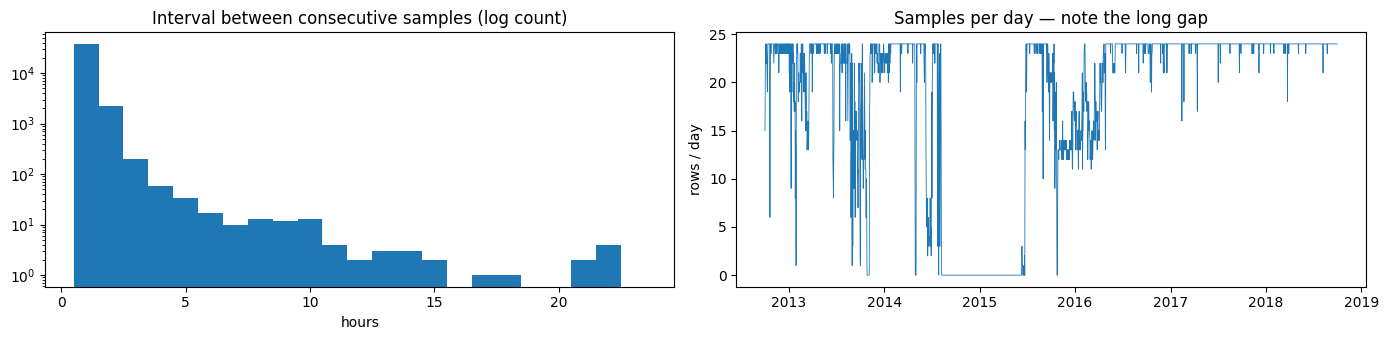

In [7]:
gaps = tr.index.to_series().diff().dropna()
print("Most common sampling intervals:"); print(gaps.value_counts().head(5))
big = gaps.sort_values(ascending=False).head(3)
print("\nLargest gaps:"); [print(f"  {g}  ending at {t}") for t, g in big.items()]

fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
ax[0].hist(gaps.dt.total_seconds() / 3600, bins=np.arange(0.5, 24.5, 1), log=True, color="tab:blue")
ax[0].set(title="Interval between consecutive samples (log count)", xlabel="hours")
daily_n = tr["traffic_volume"].resample("D").count()
ax[1].plot(daily_n.index, daily_n.values, lw=0.6); ax[1].set(title="Samples per day — note the long gap", ylabel="rows / day")
plt.tight_layout(); plt.show()

### Continuous vs discrete time  *(slide 23)*
- **Temperature** exists at every instant (continuous), so we sample it and **connect the samples with a line**.
- **Thunderstorm hours per month** is a count per bin (discrete), so **bars** are the right mark.
- Wilke: a line implies continuity. Don't connect **unordered categories** such as weather types.

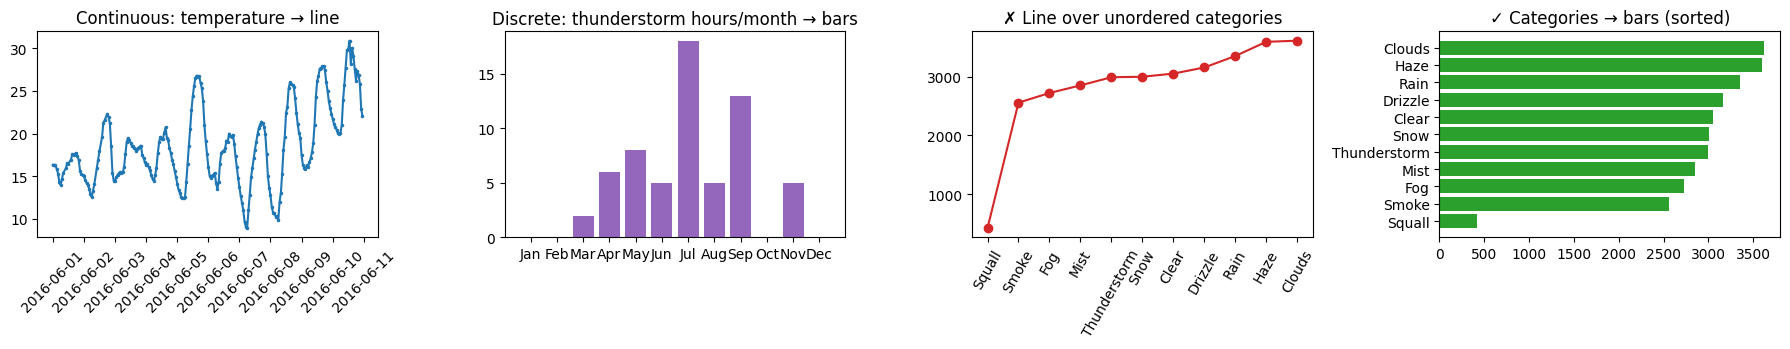

In [8]:
wk = tr.loc["2016-06-01":"2016-06-10"]
storms_m = tr[tr.weather_main.eq("Thunderstorm")].resample("MS").size().loc["2016"]
by_weather = tr.groupby("weather_main")["traffic_volume"].mean().sort_values()

fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
ax[0].plot(wk.index, wk.temp_c, marker=".", ms=3); ax[0].set_title("Continuous: temperature → line"); ax[0].tick_params(axis="x", rotation=45)
ax[1].bar(storms_m.index.strftime("%b"), storms_m.values, color="tab:purple"); ax[1].set_title("Discrete: thunderstorm hours/month → bars")
ax[2].plot(by_weather.index, by_weather.values, marker="o", c="tab:red"); ax[2].set_title("✗ Line over unordered categories"); ax[2].tick_params(axis="x", rotation=60)
ax[3].barh(by_weather.index, by_weather.values, color="tab:green"); ax[3].set_title("✓ Categories → bars (sorted)")
plt.tight_layout(); plt.show()

## 2. Time-series visualization  *(slide 26)*
The standard idiom is a **line chart with time on x**. Use dots and lines for sparse data and lines alone for dense data. With many series, use direct labels or small multiples.

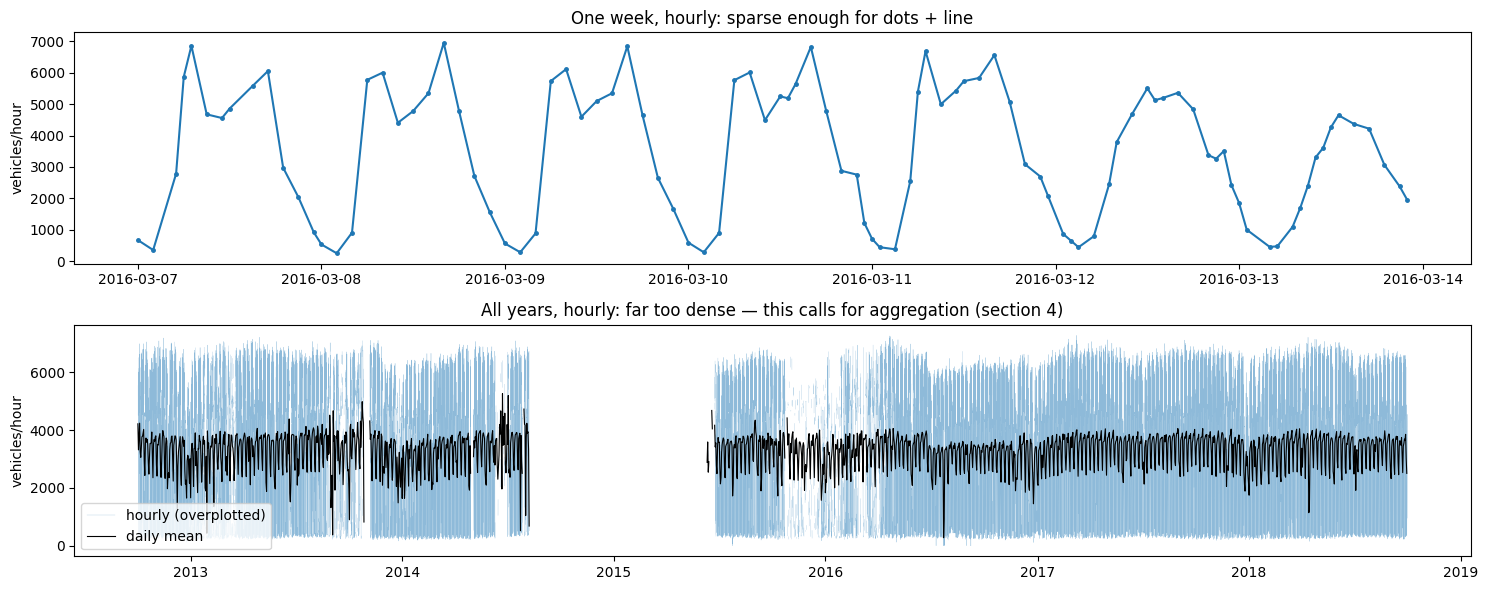

In [9]:
fig, ax = plt.subplots(2, 1, figsize=(15, 6))
week = tr.loc["2016-03-07":"2016-03-13", "traffic_volume"]
ax[0].plot(week.index, week.values, "-o", ms=2.5); ax[0].set(title="One week, hourly: sparse enough for dots + line", ylabel="vehicles/hour")
hr = tr.traffic_volume.asfreq("h")                     # NaN in gaps, so the line breaks instead of bridging them
ax[1].plot(hr.index, hr.values, lw=0.2, alpha=0.5, label="hourly (overplotted)")
d = tr.traffic_volume.resample("D").mean()
ax[1].plot(d.index, d.values, lw=0.8, c="k", label="daily mean")
ax[1].set(title="All years, hourly: far too dense — this calls for aggregation (section 4)", ylabel="vehicles/hour"); ax[1].legend(loc="lower left")
plt.tight_layout(); plt.show()

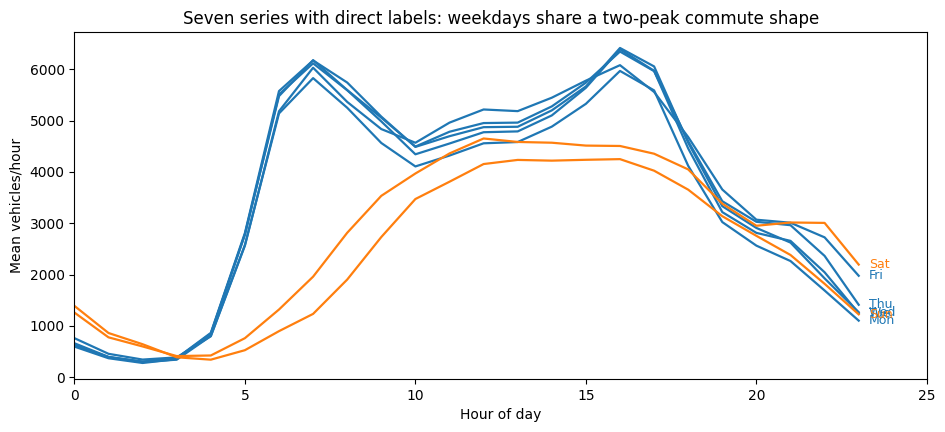

In [10]:
# Multiple series with DIRECT LABELS instead of a legend
prof = tr.groupby(["dow", "hour"])["traffic_volume"].mean().unstack(0)
fig, ax = plt.subplots(figsize=(11, 4.5))
for d_ in prof.columns:
    c = "tab:orange" if d_ >= 5 else "tab:blue"
    ax.plot(prof.index, prof[d_], c=c, lw=1.6)
    ax.text(23.3, prof[d_].iloc[-1], DOW[d_], color=c, va="center", fontsize=9)
ax.set(xlim=(0, 25), xlabel="Hour of day", ylabel="Mean vehicles/hour", title="Seven series with direct labels: weekdays share a two-peak commute shape")
plt.show()

### Connected scatter plot
Two variables plotted against each other, with the points **joined in time order**. This shows cycles well, but the direction and the start and end must be marked explicitly.

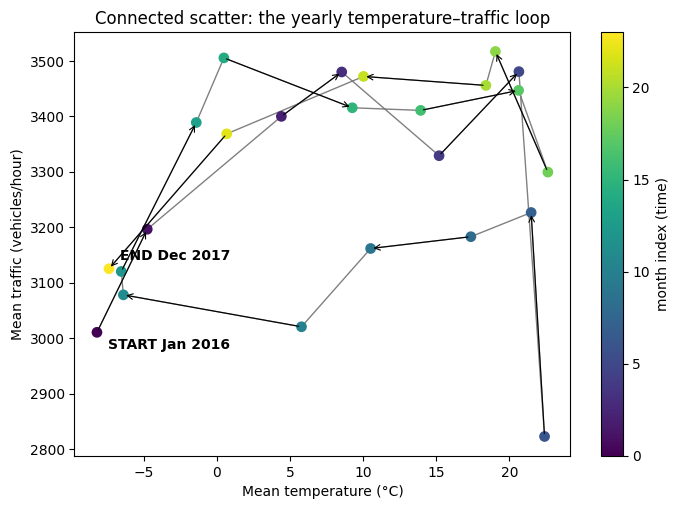

In [11]:
m = tr.loc["2016-01":"2017-12"].resample("MS").agg({"temp_c": "mean", "traffic_volume": "mean"})
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(m.temp_c, m.traffic_volume, c="grey", lw=1, zorder=1)
sc = ax.scatter(m.temp_c, m.traffic_volume, c=np.arange(len(m)), cmap="viridis", s=45, zorder=2)
for i in range(0, len(m) - 1, 2):
    ax.annotate("", xy=(m.temp_c.iloc[i+1], m.traffic_volume.iloc[i+1]), xytext=(m.temp_c.iloc[i], m.traffic_volume.iloc[i]),
                arrowprops=dict(arrowstyle="->", color="k", lw=0.8))
ax.annotate("START Jan 2016", (m.temp_c.iloc[0], m.traffic_volume.iloc[0]), xytext=(8, -12), textcoords="offset points", fontweight="bold")
ax.annotate("END Dec 2017", (m.temp_c.iloc[-1], m.traffic_volume.iloc[-1]), xytext=(8, 6), textcoords="offset points", fontweight="bold")
plt.colorbar(sc, label="month index (time)")
ax.set(xlabel="Mean temperature (°C)", ylabel="Mean traffic (vehicles/hour)", title="Connected scatter: the yearly temperature–traffic loop")
plt.show()

## 3. Temporal encoding — five ways to show *hour of day*  *(slide 25)*
The same weekday hourly profile, with time encoded as **position**, **angle** (cyclic), **colour**, and **order/connection**. **Animation** comes in later sections.
Position is the most accurate channel, so prefer it for detailed comparison.

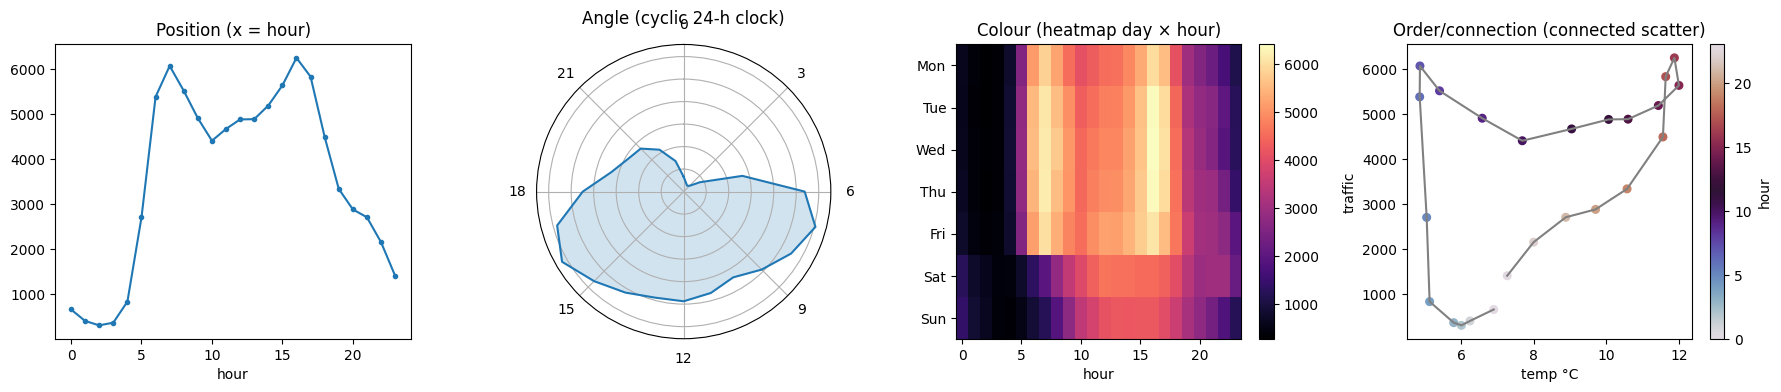

In [12]:
wd = tr[~tr.weekend].groupby("hour")["traffic_volume"].mean()
heat = tr.groupby(["dow", "hour"])["traffic_volume"].mean().unstack()

fig = plt.figure(figsize=(18, 4))
a1 = fig.add_subplot(1, 4, 1); a1.plot(wd.index, wd.values, "-o", ms=3); a1.set(title="Position (x = hour)", xlabel="hour")
a2 = fig.add_subplot(1, 4, 2, projection="polar")
th = 2 * np.pi * np.r_[wd.index, 24] / 24
a2.plot(th, np.r_[wd.values, wd.values[0]]); a2.fill(th, np.r_[wd.values, wd.values[0]], alpha=0.2)
a2.set_theta_zero_location("N"); a2.set_theta_direction(-1); a2.set_xticks(2*np.pi*np.arange(0, 24, 3)/24); a2.set_xticklabels(range(0, 24, 3))
a2.set_title("Angle (cyclic 24-h clock)", pad=15); a2.set_yticklabels([])
a3 = fig.add_subplot(1, 4, 3); im = a3.imshow(heat, aspect="auto", cmap="magma")
a3.set(title="Colour (heatmap day × hour)", xlabel="hour", yticks=range(7), yticklabels=DOW); plt.colorbar(im, ax=a3)
a4 = fig.add_subplot(1, 4, 4)
temp_h = tr[~tr.weekend].groupby("hour")["temp_c"].mean()
a4.plot(temp_h.values, wd.values, c="grey"); s = a4.scatter(temp_h.values, wd.values, c=wd.index, cmap="twilight", s=30)
a4.set(title="Order/connection (connected scatter)", xlabel="temp °C", ylabel="traffic"); plt.colorbar(s, ax=a4, label="hour")
plt.tight_layout(); plt.show()

**Discuss:** which view makes it easiest to read the *exact* traffic at 5 pm (position)? Which shows that 23:00 wraps round to 00:00 (angle)? Which shows day and hour together (colour)?

## 4. Temporal aggregation and moving averages  *(slides 27–28)*
Aggregation turns many time steps into fewer summaries: **hour → day → week → month**. It reduces clutter but loses detail.

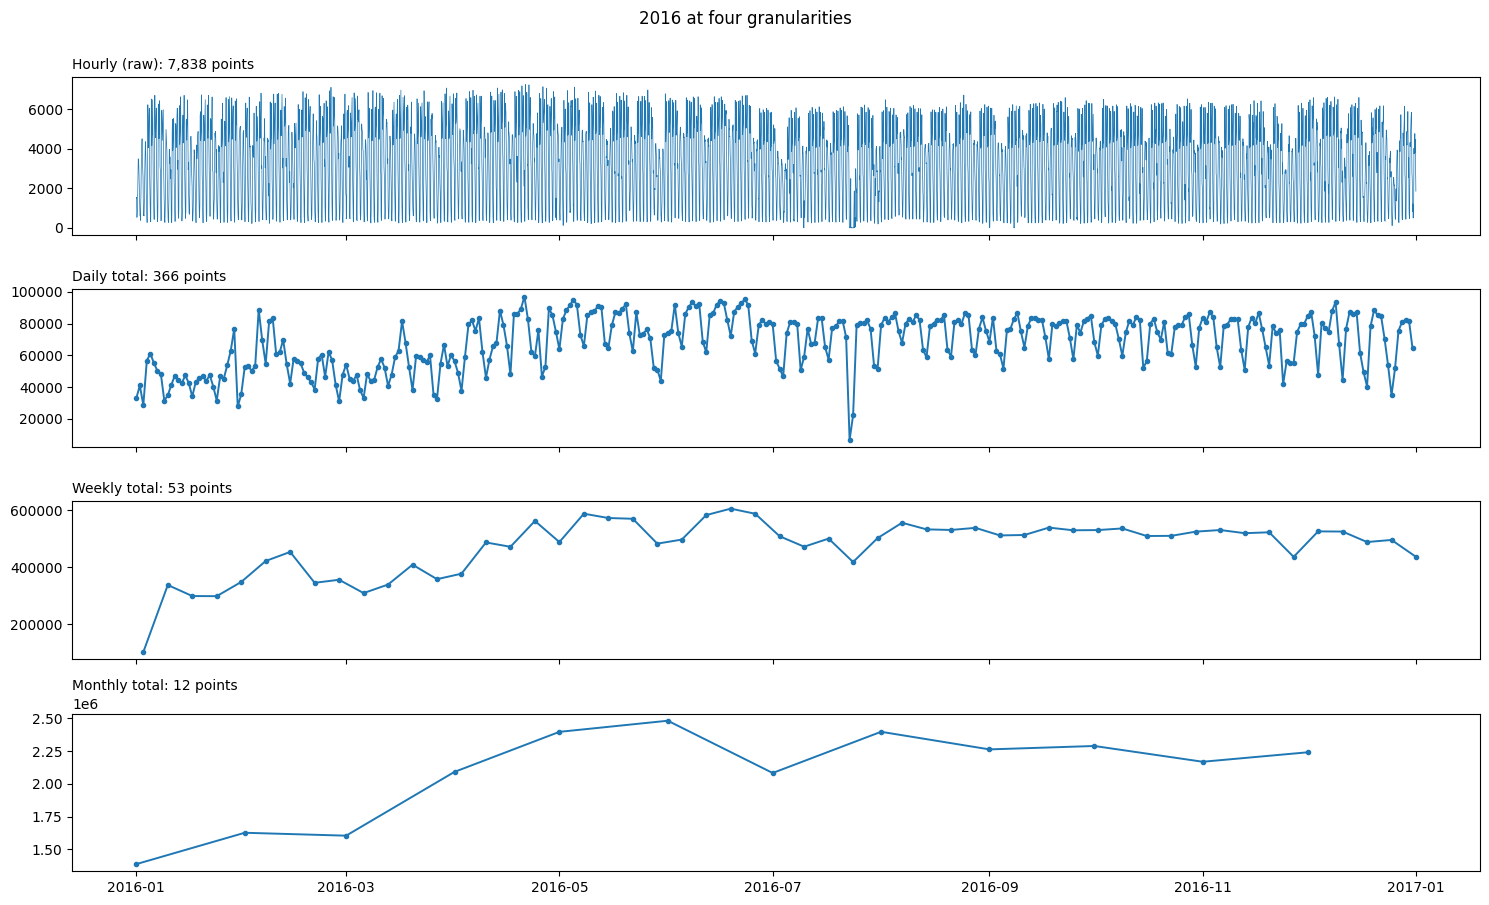

Weeks don't nest in months: 9 is the ISO week of 29 Feb 2016, and it ends in March.


In [13]:
s = tr["traffic_volume"].loc["2016"]
levels = {"Hourly (raw)": s, "Daily total": s.resample("D").sum(min_count=1), "Weekly total": s.resample("W").sum(min_count=1), "Monthly total": s.resample("MS").sum(min_count=1)}
fig, axs = plt.subplots(4, 1, figsize=(15, 9), sharex=True)
for ax, (name, ser) in zip(axs, levels.items()):
    ax.plot(ser.index, ser.values, lw=0.5 if "Hour" in name else 1.4, marker=None if "Hour" in name else ".")
    ax.set_title(f"{name}: {len(ser):,} points", loc="left", fontsize=10)
plt.suptitle("2016 at four granularities", y=1.0); plt.tight_layout(); plt.show()
print("Weeks don't nest in months:", pd.Timestamp("2016-02-29").isocalendar().week, "is the ISO week of 29 Feb 2016, and it ends in March.")

### Numerical 5 in code: moving averages and points per pixel

In [14]:
sales = pd.Series([12, 15, 11, 18, 20, 14, 16], index=[f"Day {i}" for i in range(1, 8)])
print("(a) 3-day CENTRED moving average:"); print(sales.rolling(3, center=True).mean().round(2).to_string())
print(f"(b) Weekly total = {sales.sum()}, mean = {sales.mean():.2f}")
days, width = 3 * 365, 900
for name, n in [("daily", days), ("weekly", days // 7), ("monthly", 36)]:
    print(f"(c) {name:8s}: {n:5d} points → {n/width:.2f} points/pixel  ({width/n:.1f} px per point)")

(a) 3-day CENTRED moving average:
Day 1      NaN
Day 2    12.67
Day 3    14.67
Day 4    16.33
Day 5    17.33
Day 6    16.67
Day 7      NaN
(b) Weekly total = 106, mean = 15.14
(c) daily   :  1095 points → 1.22 points/pixel  (0.8 px per point)
(c) weekly  :   156 points → 0.17 points/pixel  (5.8 px per point)
(c) monthly :    36 points → 0.04 points/pixel  (25.0 px per point)


In [ ]:
daily = tr["traffic_volume"].resample("D").sum(min_count=1).loc["2016"] / 1000
fig, ax = plt.subplots(1, 2, figsize=(16, 4.2))
ax[0].plot(daily.index, daily.values, c="lightgrey", lw=0.8, label="daily")
for k, c in [(7, "tab:blue"), (30, "tab:red")]:
    ax[0].plot(daily.index, daily.rolling(k, center=True).mean(), c=c, lw=1.8, label=f"{k}-day centred MA")
ax[0].set(title="Bigger window = smoother, but short events (holidays) vanish", ylabel="thousand vehicles/day"); ax[0].legend()

z = daily.loc["2016-06-15":"2016-08-15"]
ax[1].plot(z.index, z.values, c="lightgrey", marker=".", label="daily")
ax[1].plot(z.index, z.rolling(7, center=True).mean(), c="tab:blue", lw=2, label="7-day centred")
ax[1].plot(z.index, z.rolling(7).mean(), c="tab:orange", lw=2, ls="--", label="7-day trailing (lags ~3 days)")
ax[1].axvline(pd.Timestamp("2016-07-04"), c="k", ls=":"); ax[1].text(pd.Timestamp("2016-07-04"), z.max(), " 4 July", va="top")
ax[1].set(title="Plot the average at the window CENTRE to avoid lag"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. Temporal filtering and dynamic queries  *(slide 29)*
Filtering **keeps full detail** for what remains and hides the rest. Below are conditional filters (weekday vs weekend, peak hours), then an **overview + detail** view with a range slider (Shneiderman: *overview first, zoom and filter, details on demand*).

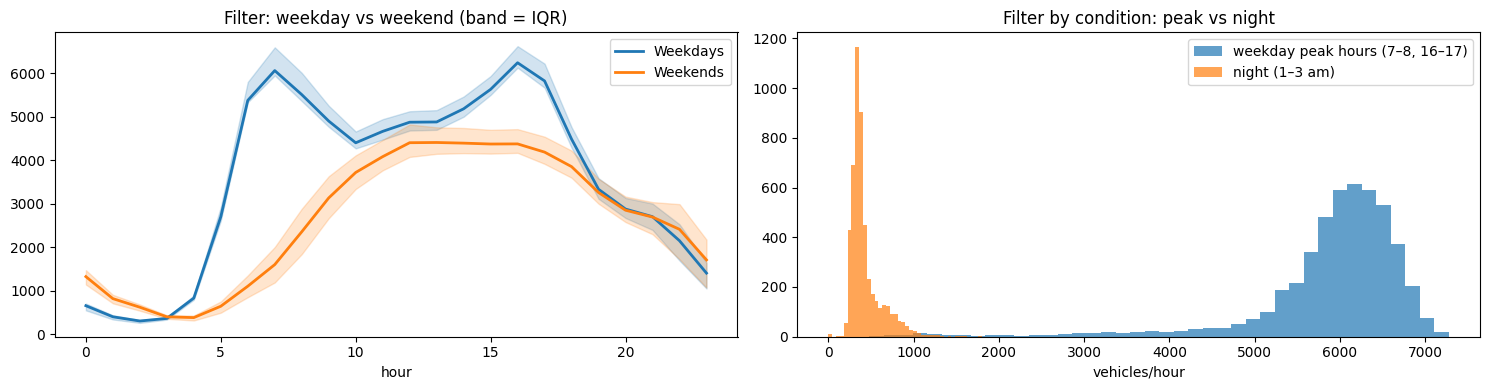

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for flag, lab, c in [(False, "Weekdays", "tab:blue"), (True, "Weekends", "tab:orange")]:
    g = tr[tr.weekend == flag].groupby("hour")["traffic_volume"]
    ax[0].plot(g.mean().index, g.mean(), c=c, lw=2, label=lab)
    ax[0].fill_between(g.mean().index, g.quantile(0.25), g.quantile(0.75), color=c, alpha=0.2)
ax[0].set(title="Filter: weekday vs weekend (band = IQR)", xlabel="hour"); ax[0].legend()
peak = tr[(~tr.weekend) & tr.hour.isin([7, 8, 16, 17])]
ax[1].hist(peak.traffic_volume, bins=40, alpha=0.7, label="weekday peak hours (7–8, 16–17)")
ax[1].hist(tr[tr.hour.isin([1, 2, 3])].traffic_volume, bins=40, alpha=0.7, label="night (1–3 am)")
ax[1].set(title="Filter by condition: peak vs night", xlabel="vehicles/hour"); ax[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
dd = tr["traffic_volume"].resample("D").sum(min_count=1).rename("vehicles/day").reset_index()
fig = px.line(dd, x="date_time", y="vehicles/day", title="Dynamic query: drag the range slider or use the buttons (overview + detail)")
fig.update_xaxes(rangeslider_visible=True, rangeselector=dict(buttons=[
    dict(count=7, label="1w", step="day", stepmode="backward"), dict(count=1, label="1m", step="month", stepmode="backward"),
    dict(count=6, label="6m", step="month", stepmode="backward"), dict(count=1, label="1y", step="year", stepmode="backward"),
    dict(step="all")]))
fig.update_layout(height=450); fig.show()

## 6. Events over time  *(slide 24)*
- **Point events:** holidays (one day each), shown as an **event strip / rug**.
- **Counts per bin:** thunderstorm hours per week, a **histogram over time** that reveals **bursts** and **gaps**.
- **Aligning to a reference:** traffic around each holiday, re-indexed to *days since the holiday*.

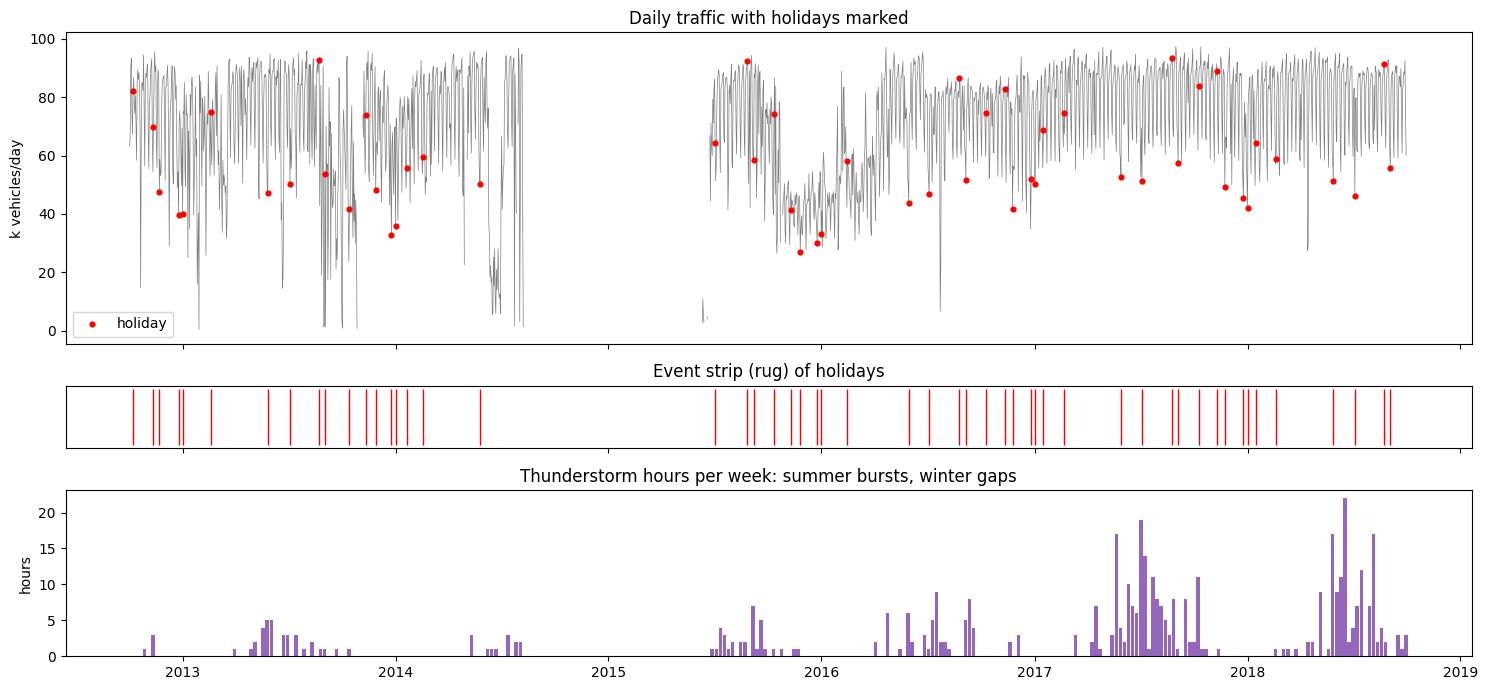

In [16]:
dsum = tr["traffic_volume"].resample("D").sum(min_count=1) / 1000
hdays = pd.to_datetime(hol_by_day.index)
fig, ax = plt.subplots(3, 1, figsize=(15, 7), sharex=True, gridspec_kw=dict(height_ratios=[3, 0.6, 1.6]))
ax[0].plot(dsum.index, dsum.values, lw=0.5, c="grey"); ax[0].scatter(hdays, dsum.reindex(hdays), c="red", s=12, zorder=3, label="holiday")
ax[0].set(ylabel="k vehicles/day", title="Daily traffic with holidays marked"); ax[0].legend()
ax[1].vlines(hdays, 0, 1, color="red", lw=1); ax[1].set(yticks=[], title="Event strip (rug) of holidays")
storm_w = tr[tr.weather_main.eq("Thunderstorm")].resample("W").size()
ax[2].bar(storm_w.index, storm_w.values, width=6, color="tab:purple"); ax[2].set(ylabel="hours", title="Thunderstorm hours per week: summer bursts, winter gaps")
plt.tight_layout(); plt.show()

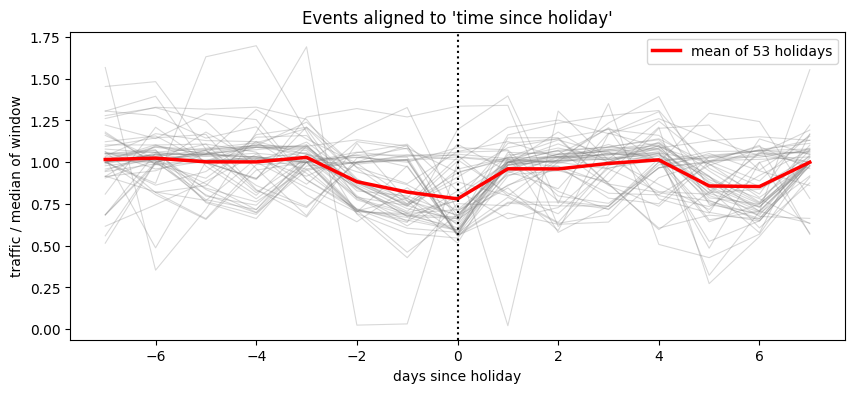

In [17]:
# Align events to a common reference: ±7 days around each holiday
rows = []
for h in hdays:
    win = dsum.reindex(pd.date_range(h - pd.Timedelta(days=7), h + pd.Timedelta(days=7)))
    if win.notna().sum() > 10:
        rows.append(pd.Series(win.values / np.nanmedian(win.values), index=np.arange(-7, 8)))
aligned = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(aligned.T, c="grey", alpha=0.3, lw=0.8); ax.plot(aligned.mean(), c="red", lw=2.5, label=f"mean of {len(aligned)} holidays")
ax.axvline(0, ls=":", c="k"); ax.set(xlabel="days since holiday", ylabel="traffic / median of window", title="Events aligned to 'time since holiday'")
ax.legend(); plt.show()

## 7. Timeline visualization  *(slide 30)*
Intervals shown as bars on a time axis (a **Gantt chart**): each storm of one hurricane season is a **lane**, coloured by peak wind, with **milestones** as vertical lines.

In [18]:
season = hu.groupby("year")["ID"].nunique().idxmax() if 2005 not in hu.year.values else 2005
life = (hu[hu.year == season].groupby("storm").agg(start=("time", "min"), end=("time", "max"), peak_wind=("wind", "max"))
        .sort_values("start").reset_index())
fig = px.timeline(life, x_start="start", x_end="end", y="storm", color="peak_wind", color_continuous_scale="YlOrRd",
                  title=f"Timeline of the {season} Atlantic season: one lane per storm (interval = lifetime)")
fig.update_yaxes(autorange="reversed")
for label, date in [("Aug 1", f"{season}-08-01"), ("Sep 1", f"{season}-09-01"), ("Oct 1", f"{season}-10-01")]:
    fig.add_vline(x=pd.Timestamp(date).timestamp() * 1000, line_dash="dot", line_color="grey")
fig.update_layout(height=max(400, 22 * len(life))); fig.show()

## 8. Temporal sampling, Nyquist and aliasing  *(slides 10–11)*
Traffic has a strong **24-hour cycle**. By Nyquist–Shannon we must sample at $f_s > 2f$, i.e. **more often than every 12 hours**.
Sampling more sparsely creates **aliasing**: false slow cycles, like the wagon-wheel effect.

In [19]:
def aliased_period(true_period, sample_interval):
    """Apparent period (same units) when a cycle is sampled every `sample_interval`."""
    f, fs = 1 / true_period, 1 / sample_interval
    fa = abs(f - fs * round(f / fs))                 # fold the frequency into [0, fs/2]
    return np.inf if fa == 0 else 1 / fa

print("Numerical 2")
f_max = 60 / 15
print(f"(a) f_max = {f_max:.0f} cycles/h → fs > {2*f_max:.0f} samples/h → Δt < {60/(2*f_max):.1f} min")
print(f"(b) 50-min cycle sampled hourly appears as a {aliased_period(50, 60)/60:.1f}-hour cycle")
print(f"(c) 24 h in 12 s → compression {24*3600/12:,.0f}:1 → 1 s of animation = {24*3600/12/3600:.0f} h of data")
print("\nTraffic 24-h cycle sampled every 23 h looks like a", round(aliased_period(24, 23)), "hour cycle (≈ 23 days!)")

Numerical 2
(a) f_max = 4 cycles/h → fs > 8 samples/h → Δt < 7.5 min
(b) 50-min cycle sampled hourly appears as a 5.0-hour cycle
(c) 24 h in 12 s → compression 7,200:1 → 1 s of animation = 2 h of data

Traffic 24-h cycle sampled every 23 h looks like a 552 hour cycle (≈ 23 days!)


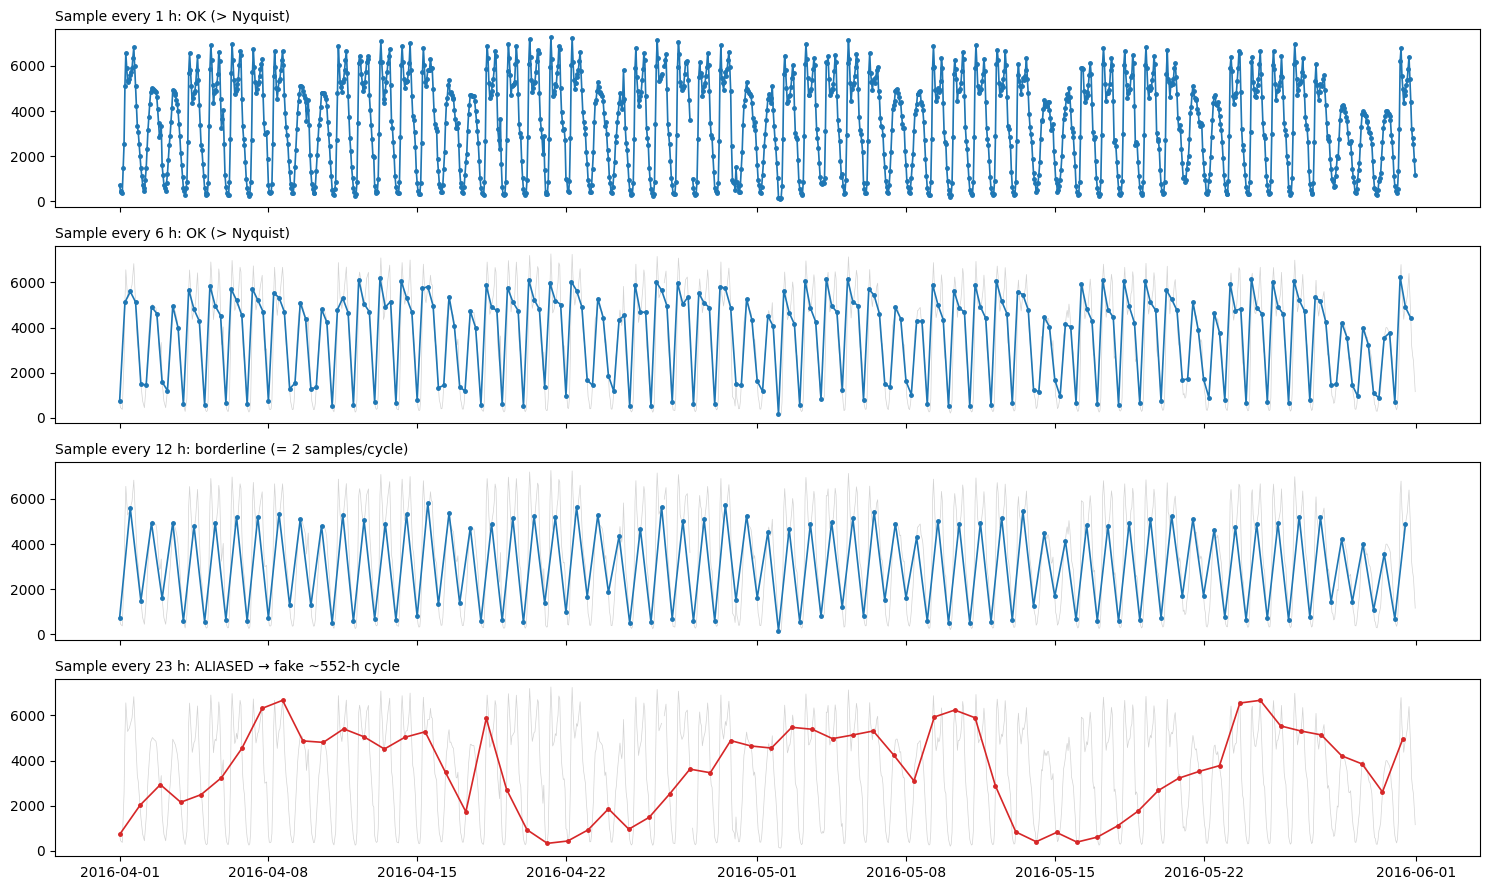

In [20]:
seg = tr["traffic_volume"].loc["2016-04-01":"2016-05-31"].asfreq("h").interpolate(limit=3)
fig, axs = plt.subplots(4, 1, figsize=(15, 9), sharex=True)
for ax, step in zip(axs, [1, 6, 12, 23]):
    sm = seg.iloc[::step]
    ax.plot(seg.index, seg.values, c="lightgrey", lw=0.5)
    ax.plot(sm.index, sm.values, "-o", ms=2.5, lw=1.2, c="tab:red" if step > 12 else "tab:blue")
    status = "OK (> Nyquist)" if step < 12 else ("borderline (= 2 samples/cycle)" if step == 12 else f"ALIASED → fake ~{aliased_period(24, step):.0f}-h cycle")
    ax.set_title(f"Sample every {step} h: {status}", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

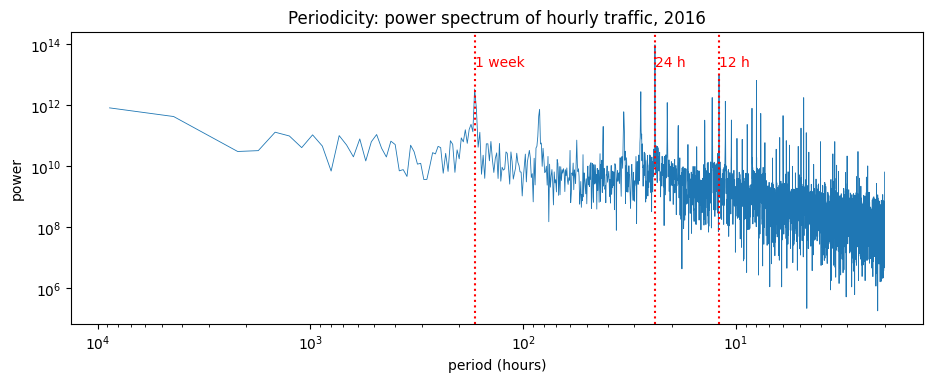

In [21]:
# Finding periods: the frequency spectrum of one continuous year shows the daily and weekly cycles
yr = tr["traffic_volume"].loc["2016"].asfreq("h").interpolate(limit=6).dropna()
x = yr.values - yr.values.mean()
spec = np.abs(np.fft.rfft(x)) ** 2
freq = np.fft.rfftfreq(len(x), d=1.0)                    # cycles per hour
period = 1 / freq[1:]
plt.figure(figsize=(11, 3.8)); plt.loglog(period, spec[1:], lw=0.6)
for p, l in [(24, "24 h"), (12, "12 h"), (168, "1 week")]:
    plt.axvline(p, ls=":", c="red"); plt.text(p, spec.max() / 5, l, color="red")
plt.gca().invert_xaxis(); plt.xlabel("period (hours)"); plt.ylabel("power"); plt.title("Periodicity: power spectrum of hourly traffic, 2016"); plt.show()

## 9. Frame rate and animation timing  *(slides 7–9, 14)*
**Frame budget = 1000 ms / fps.** Keep the *rendering rate* (fps) separate from the *data rate* (time steps per second).

In [22]:
def frame_budget_ms(fps): return 1000 / fps

print("Numerical 1")
months, hold, fps = 120, 0.5, 24
print(f"(a) duration = {months*hold:.0f} s   (b) frames = {months*hold*fps:,.0f}   (c) frames/month = {hold*fps:.0f}")
print(f"(d) 30 s / 120 months = {30/120} s/month → 6 frames / 0.25 s = {6/(30/120):.0f} fps")
cost = 50_000 * 0.4e-3
print(f"(e) 50,000 × 0.4 µs = {cost:.0f} ms > {frame_budget_ms(60):.1f} ms budget → max {1000/cost:.0f} fps; "
      f"≤ {int(frame_budget_ms(60)/0.4e-3):,} particles for 60 fps")
for f in [10, 24, 30, 60, 120]: print(f"   {f:3d} fps → {frame_budget_ms(f):5.1f} ms per frame")

Numerical 1
(a) duration = 60 s   (b) frames = 1,440   (c) frames/month = 12
(d) 30 s / 120 months = 0.25 s/month → 6 frames / 0.25 s = 24 fps
(e) 50,000 × 0.4 µs = 20 ms > 16.7 ms budget → max 50 fps; ≤ 41,666 particles for 60 fps
    10 fps → 100.0 ms per frame
    24 fps →  41.7 ms per frame
    30 fps →  33.3 ms per frame
    60 fps →  16.7 ms per frame
   120 fps →   8.3 ms per frame


### Easing: slow-in / slow-out  *(Numerical 3)*
Smoothstep $s(u)=3u^2-2u^3$ starts and ends at zero speed, so the eye can lock on to the start and end positions.

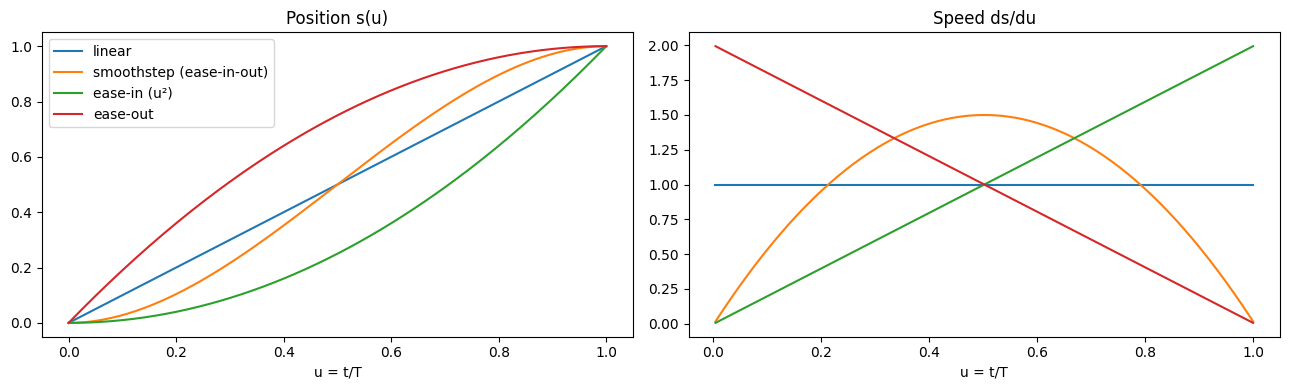

Numerical 3
(a) t = 0.25 s → linear x = 200.0 px, smoothstep x = 162.5 px
(b) peak speed: linear 400 px/s, smoothstep 600 px/s (at u = 0.5)
(c) largest per-frame jump with easing ≈ 20.0 px (analytic 600/30 = 20 px); first jump = 1.30 px


In [23]:
ease = {"linear": lambda u: u, "smoothstep (ease-in-out)": lambda u: 3*u**2 - 2*u**3,
        "ease-in (u²)": lambda u: u**2, "ease-out": lambda u: 1 - (1-u)**2}
u = np.linspace(0, 1, 200)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, f in ease.items():
    ax[0].plot(u, f(u), label=k); ax[1].plot(u[1:], np.diff(f(u)) / np.diff(u), label=k)
ax[0].set(title="Position s(u)", xlabel="u = t/T"); ax[1].set(title="Speed ds/du", xlabel="u = t/T"); ax[0].legend()
plt.tight_layout(); plt.show()

x0, x1, T, fps = 100, 500, 1.0, 30; D = x1 - x0; ss = ease["smoothstep (ease-in-out)"]
print("Numerical 3")
print(f"(a) t = 0.25 s → linear x = {x0 + D*0.25:.1f} px, smoothstep x = {x0 + D*ss(0.25):.1f} px")
print(f"(b) peak speed: linear {D/T:.0f} px/s, smoothstep {1.5*D/T:.0f} px/s (at u = 0.5)")
frames = x0 + D * ss(np.linspace(0, 1, int(T*fps) + 1))
print(f"(c) largest per-frame jump with easing ≈ {np.diff(frames).max():.1f} px (analytic 600/30 = 20 px); first jump = {np.diff(frames)[0]:.2f} px")

In [24]:
# Same 2-second motion at 6 fps vs 30 fps, linear (top) vs eased (bottom).
def motion_demo(fps, T=2.0):
    n = int(T * fps)
    fig, ax = plt.subplots(figsize=(6, 1.8)); ax.set(xlim=(0, 1), ylim=(-0.5, 1.5), yticks=[0, 1], yticklabels=["eased", "linear"]); ax.set_xticks([])
    lin, = ax.plot([], [], "o", ms=14, c="tab:blue"); eas, = ax.plot([], [], "o", ms=14, c="tab:red")
    ax.set_title(f"{fps} fps  ({1000/fps:.0f} ms per frame)")
    def upd(i):
        uu = min(i / (n - 1), 1)
        lin.set_data([0.05 + 0.9*uu], [1]); eas.set_data([0.05 + 0.9*(3*uu**2 - 2*uu**3)], [0]); return lin, eas
    return animation.FuncAnimation(fig, upd, frames=n + fps // 2, interval=1000 / fps)
display(show_anim(motion_demo(6)))
display(show_anim(motion_demo(30)))

## 10. Motion as a visual variable  *(slide 6)*
Motion **pops out preattentively**. Munzner's safe use is as a two-level identity channel (*moves / doesn't move*) for highlighting.
Below, each dot is one day of 2016 (x = day of year, y = daily traffic). **Holidays wiggle**: find them without reading any labels.

In [25]:
d16 = (tr["traffic_volume"].resample("D").sum(min_count=1) / 1000).loc["2016"].dropna()
is_h = d16.index.isin(hdays)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.scatter(d16.index.dayofyear[~is_h], d16.values[~is_h], s=12, c="tab:blue")
mv = ax.scatter(d16.index.dayofyear[is_h], d16.values[is_h], s=30, c="tab:blue")
ax.set(xlabel="day of year 2016", ylabel="k vehicles/day", title="Motion as highlighting: the moving dots are holidays")
base = np.column_stack([d16.index.dayofyear[is_h], d16.values[is_h]])
def upd(i):
    mv.set_offsets(base + np.column_stack([np.zeros(is_h.sum()), 1.5 * np.sin(i / 2) * np.ones(is_h.sum())])); return (mv,)
show_anim(animation.FuncAnimation(fig, upd, frames=24, interval=60))

Now imagine *every* dot wiggling at a different rate. Motion can't be ignored, so used too much it becomes distracting flicker.

## 11. Animated transitions  *(slides 12–13)*
Munzner calls transitions *one of the best-justified uses of animation*: the eye **tracks each mark** from the old state to the new one.
The buttons switch the hourly profile between weekdays and weekends, either with a **smooth 1 s ease-in-out transition** or with a **jump cut**.

In [26]:
wk_prof = tr[~tr.weekend].groupby("hour")["traffic_volume"].mean()
we_prof = tr[tr.weekend].groupby("hour")["traffic_volume"].mean()
mk = lambda s: go.Bar(x=s.index, y=s.values, marker_color=["darkorange" if h in (7, 8, 16, 17) else "steelblue" for h in s.index])
fig = go.Figure(data=[mk(wk_prof)], frames=[go.Frame(data=[mk(wk_prof)], name="Weekday"), go.Frame(data=[mk(we_prof)], name="Weekend")])
btn = lambda lbl, fr, dur: dict(label=lbl, method="animate",
                                args=[[fr], dict(frame=dict(duration=dur, redraw=False), transition=dict(duration=dur, easing="cubic-in-out"), mode="immediate")])
fig.update_layout(title="Transition vs jump cut (the y-axis is FIXED so heights stay comparable)",
                  yaxis=dict(range=[0, 6000], title="mean vehicles/hour"), xaxis_title="hour", height=430,
                  updatemenus=[dict(type="buttons", direction="right", x=0, y=1.15, xanchor="left", buttons=[
                      btn("Weekday — smooth 1 s", "Weekday", 1000), btn("Weekend — smooth 1 s", "Weekend", 1000),
                      btn("Weekday — jump cut", "Weekday", 0), btn("Weekend — jump cut", "Weekend", 0)])])
fig.show()

### Staging (Heer & Robertson)
**One kind of change per stage.** Stage 1: the dots move **vertically** to their weekend values. Stage 2: they **re-sort horizontally** by the new value.
Each stage lasts about 1 s with ease-in-out, and the final state is held so it can be read.

In [27]:
hours = np.arange(24)
rank_wd = np.argsort(np.argsort(-wk_prof.values)); rank_we = np.argsort(np.argsort(-we_prof.values))
fps, T = 20, 1.0; n = int(fps * T); hold = 12
def smooth(u): return 3*u**2 - 2*u**3
fig, ax = plt.subplots(figsize=(11, 4))
sc = ax.scatter(rank_wd, wk_prof.values, c=hours, cmap="twilight", s=60)
lbl = [ax.text(rank_wd[h], wk_prof.values[h] + 150, str(h), ha="center", fontsize=7) for h in hours]
ax.set(xlim=(-1, 24), ylim=(0, 6000), xlabel="rank (sorted by value)", ylabel="mean vehicles/hour"); ttl = ax.set_title("")
def state(i):
    if i < hold: return rank_wd, wk_prof.values, "Start: weekday values, sorted"
    i -= hold
    if i < n: u = smooth(i / n); return rank_wd, wk_prof.values + u * (we_prof.values - wk_prof.values), "Stage 1: values change (vertical only)"
    i -= n
    if i < hold: return rank_wd, we_prof.values, "Hold"
    i -= hold
    if i < n: u = smooth(i / n); return rank_wd + u * (rank_we - rank_wd), we_prof.values, "Stage 2: re-sort (horizontal only)"
    return rank_we, we_prof.values, "End: weekend values, sorted"
def upd(i):
    x, y, t = state(i); sc.set_offsets(np.column_stack([x, y])); ttl.set_text(t)
    for h in hours: lbl[h].set_position((x[h], y[h] + 150))
    return [sc, ttl, *lbl]
show_anim(animation.FuncAnimation(fig, upd, frames=3 * hold + 2 * n, interval=1000 / fps))

## 12. Change detection and change blindness  *(slide 15)*
We take the day × hour traffic heatmap and **plant one changed cell** in a copy. Then we try three ways of finding it:
1. **Side by side:** you have to compare from memory.
2. **Flicker paradigm (A → blank → B → blank):** the blank hides the motion signal, so the change is very hard to spot.
3. **Blink comparator (A ↔ B, no blank):** the change pops out as a flicker, the way Pluto was found.

The final panel is a **difference view**, which answers the question directly.

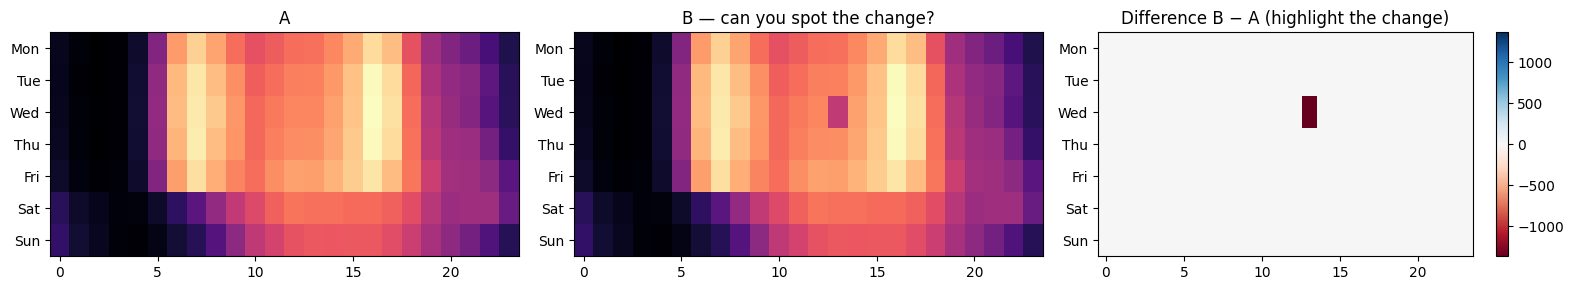

In [28]:
A = heat.values.copy(); B = A.copy()
rng_cb = np.random.default_rng(3); r, c = 2, int(rng_cb.integers(9, 15)); B[r, c] *= 0.72    # planted change
vmin, vmax = A.min(), A.max()
fig, ax = plt.subplots(1, 3, figsize=(16, 3))
for a, M, t in [(ax[0], A, "A"), (ax[1], B, "B — can you spot the change?")]:
    a.imshow(M, cmap="magma", vmin=vmin, vmax=vmax, aspect="auto"); a.set(title=t, yticks=range(7), yticklabels=DOW)
im = ax[2].imshow(B - A, cmap="RdBu", aspect="auto", vmin=-abs(B - A).max(), vmax=abs(B - A).max())
ax[2].set(title="Difference B − A (highlight the change)", yticks=range(7), yticklabels=DOW); plt.colorbar(im, ax=ax[2])
plt.tight_layout(); plt.show()

In [ ]:
def flicker(blank):
    seq = [A, None, B, None] if blank else [A, B]
    fig, ax = plt.subplots(figsize=(7, 2.6)); im = ax.imshow(A, cmap="magma", vmin=vmin, vmax=vmax, aspect="auto")
    ax.set(yticks=range(7), yticklabels=DOW, title="Flicker with blank frames" if blank else "Blink comparator (no blank)")
    def upd(i):
        M = seq[i % len(seq)]; im.set_data(np.full_like(A, np.nan) if M is None else M); return (im,)
    return animation.FuncAnimation(fig, upd, frames=len(seq) * 6, interval=250 if not blank else 300)
display(show_anim(flicker(True)))
display(show_anim(flicker(False)))
print(f"(Answer: {DOW[r]} at {c}:00)")

## 13. Animation for trends vs traces vs small multiples  *(slides 5, 16)*
Robertson et al. (2008) found that animation is engaging to present but **slowest and least accurate for analysis**. Here the same data (weekday hourly profile, month by month in 2017) is shown three ways.

In [29]:
yr_ = 2017 if 2017 in tr.year.values else int(tr.year.mode()[0])
mp = (tr[(tr.year == yr_) & ~tr.weekend].groupby(["month", "hour"])["traffic_volume"].mean().reset_index())
import calendar
mp["Month"] = mp["month"].map(lambda m_: calendar.month_abbr[m_])
order = [calendar.month_abbr[i] for i in range(1, 13)]
fig = px.line(mp, x="hour", y="traffic_volume", animation_frame="Month", category_orders={"Month": order},
              range_y=[0, 7000], markers=True, title=f"(1) ANIMATION: weekday profile per month, {yr_} — which month has the lowest 5 pm peak?")
fig.update_layout(height=420); fig.show()

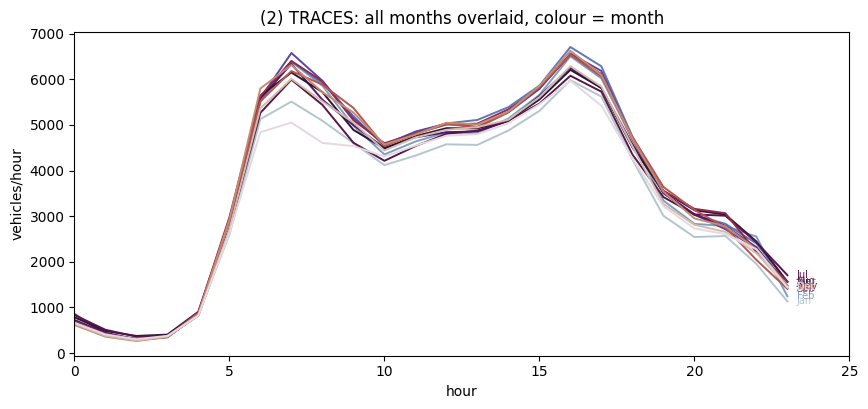

In [30]:
fig, ax = plt.subplots(figsize=(10, 4.2))
cm = plt.cm.twilight
for mth, g in mp.groupby("month"):
    ax.plot(g.hour, g.traffic_volume, c=cm(mth / 12), lw=1.4)
    ax.text(23.3, g.traffic_volume.iloc[-1], order[mth - 1], color=cm(mth / 12), fontsize=7, va="center")
ax.set(xlim=(0, 25), title="(2) TRACES: all months overlaid, colour = month", xlabel="hour", ylabel="vehicles/hour"); plt.show()

fig = px.line(mp, x="hour", y="traffic_volume", facet_col="Month", facet_col_wrap=6, category_orders={"Month": order},
              title="(3) SMALL MULTIPLES: one panel per month, shared axes", height=430)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1])); fig.show()

**Discuss:** answer *which month has the lowest 5 pm peak?* with each view. With animation you have to remember 12 frames. The traces and small multiples let your **eyes do the comparing instead of your memory**.

## 14. Animation for spatial data  *(slide 17)*
For maps, x and y are already used by space, so **time → animation** is natural. Two cautions: keep the **colour scale fixed** across frames, and offer playback controls.

In [31]:
sea = hu[(hu.year == season) & hu.time.dt.hour.eq(12)].copy()
sea["day"] = sea.time.dt.strftime("%m-%d"); sea["size"] = sea["wind"].fillna(20)
fig = px.scatter_geo(sea.sort_values("time"), lat="lat", lon="lon", color="wind", size="size",
                     hover_name="storm", animation_frame="day", range_color=[20, 160], color_continuous_scale="YlOrRd",
                     title=f"{season} season, one frame per day at 12:00 UTC (colour scale FIXED at 20–160 kt)")
fig.update_geos(lataxis_range=[5, 55], lonaxis_range=[-110, -10], showland=True, landcolor="#eee")
fig.update_layout(height=520); fig.show()

In [ ]:
# Small-multiple maps of key moments: static, comparable, printable
key_days = sorted(sea.day.unique())[:: max(1, len(sea.day.unique()) // 4)][:4]
fig = px.scatter_geo(sea[sea.day.isin(key_days)], lat="lat", lon="lon", color="wind", facet_col="day", range_color=[20, 160],
                     color_continuous_scale="YlOrRd", title="Small multiples of key dates (same fixed colour scale)")
fig.update_geos(lataxis_range=[5, 55], lonaxis_range=[-110, -10], showland=True, landcolor="#eee")
fig.update_layout(height=330); fig.show()

## 15. Motion and trajectories  *(slide 18)*
A trajectory is a sequence of $(x, y, t)$. **Direction and order must be shown explicitly**: here with a colour gradient in time, start ● and end ✕ markers, and arrows.

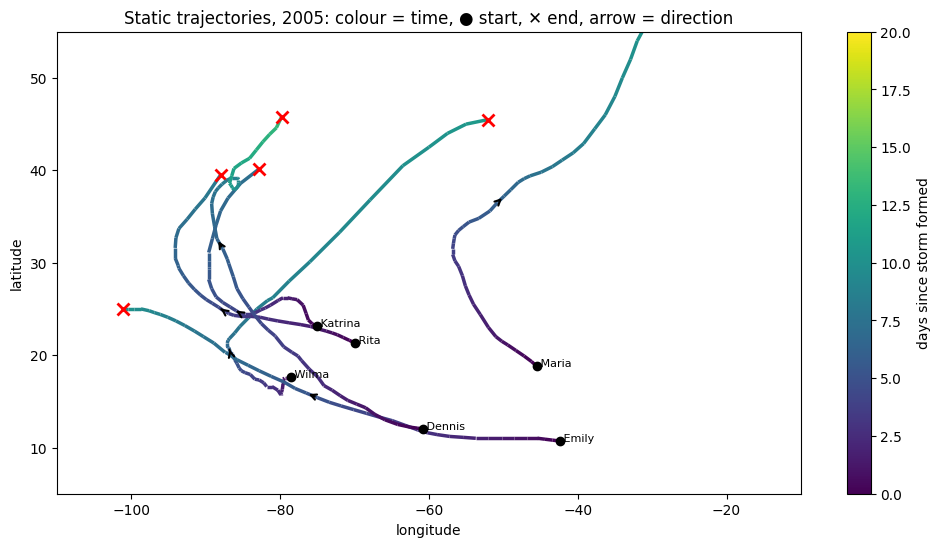

In [32]:
top = life.sort_values("peak_wind", ascending=False).head(6).storm
fig, ax = plt.subplots(figsize=(12, 6))
for sname in top:
    g = hu[hu.storm == sname].sort_values("time")
    pts = np.column_stack([g.lon, g.lat]); segs = np.stack([pts[:-1], pts[1:]], axis=1)
    tt = (g.time - g.time.min()).dt.total_seconds().values / 86400
    lc = LineCollection(segs, cmap="viridis", norm=plt.Normalize(0, 20), linewidths=2.5); lc.set_array(tt[:-1]); ax.add_collection(lc)
    ax.plot(*pts[0], "o", c="k", ms=6); ax.plot(*pts[-1], "x", c="red", ms=9, mew=2)
    mid = len(pts) // 2
    if mid + 1 < len(pts): ax.annotate("", xy=pts[mid + 1], xytext=pts[mid], arrowprops=dict(arrowstyle="->", lw=1.5))
    ax.text(*pts[0], " " + sname.split(" (")[0], fontsize=8)
plt.colorbar(lc, ax=ax, label="days since storm formed")
ax.set(xlim=(-110, -10), ylim=(5, 55), xlabel="longitude", ylabel="latitude", title=f"Static trajectories, {season}: colour = time, ● start, ✕ end, arrow = direction")
plt.show()

In [33]:
# Space-time cube: x, y on the base, time on the vertical axis
fig = go.Figure()
for sname in top:
    g = hu[hu.storm == sname].sort_values("time")
    fig.add_trace(go.Scatter3d(x=g.lon, y=g.lat, z=(g.time - pd.Timestamp(f"{season}-06-01")).dt.total_seconds() / 86400,
                               mode="lines+markers", marker=dict(size=2), line=dict(width=4), name=sname.split(" (")[0]))
fig.update_layout(title="Space-time cube: vertical axis = days since 1 June (rotate me)", height=560,
                  scene=dict(xaxis_title="lon", yaxis_title="lat", zaxis_title="day of season"))
fig.show()

## 16. Particle animation: advection, streamlines, pathlines, streaklines  *(slides 19–20)*
### Numerical 4: Euler vs RK4 in $v(x,y)=(-y,x)$

(a) Euler: p1 = (1.000, 0.100) p2 = (0.990, 0.200) p3 = (0.970, 0.299)
(b) |p3| = 1.0150 → drifts outward by 1.5 %


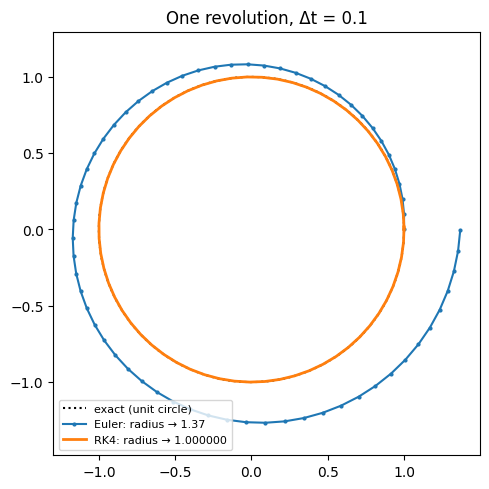

In [34]:
v_rot = lambda p, t=0: np.array([-p[1], p[0]])
def euler(p, dt, n, v=v_rot):
    out = [np.array(p, float)]
    for i in range(n): out.append(out[-1] + dt * v(out[-1], i * dt))
    return np.array(out)
def rk4(p, dt, n, v=v_rot):
    out = [np.array(p, float)]
    for i in range(n):
        q, t = out[-1], i * dt
        k1 = v(q, t); k2 = v(q + dt/2*k1, t + dt/2); k3 = v(q + dt/2*k2, t + dt/2); k4 = v(q + dt*k3, t + dt)
        out.append(q + dt / 6 * (k1 + 2*k2 + 2*k3 + k4))
    return np.array(out)
E = euler((1, 0), 0.1, 3)
print("(a) Euler:", *[f"p{i} = ({x:.3f}, {y:.3f})" for i, (x, y) in enumerate(E)][1:])
print(f"(b) |p3| = {np.linalg.norm(E[-1]):.4f} → drifts outward by {100*(np.linalg.norm(E[-1]) - 1):.1f} %")

n = 63                                                    # ≈ one full turn (2π / 0.1)
Eu, Rk = euler((1, 0), 0.1, n), rk4((1, 0), 0.1, n)
th = np.linspace(0, 2*np.pi, 200)
plt.figure(figsize=(5.5, 5.5)); plt.plot(np.cos(th), np.sin(th), "k:", label="exact (unit circle)")
plt.plot(Eu[:, 0], Eu[:, 1], "-o", ms=2, label=f"Euler: radius → {np.linalg.norm(Eu[-1]):.2f}")
plt.plot(Rk[:, 0], Rk[:, 1], "-", lw=2, label=f"RK4: radius → {np.linalg.norm(Rk[-1]):.6f}")
plt.axis("equal"); plt.legend(loc="lower left", fontsize=8); plt.title("One revolution, Δt = 0.1"); plt.show()

### Steady vs unsteady flow
In an **unsteady** (time-varying) field, the three kinds of line differ:
- **Streamline:** tangent to the field *at one instant*
- **Pathline:** the route one particle actually takes over time
- **Streakline:** all particles released from one point (a smoke trail)

We use the classic **double-gyre** flow.

In [ ]:
A_, eps, om = 0.1, 0.25, 2 * np.pi / 10
def dg(p, t):
    x, y = p[..., 0], p[..., 1]
    a = eps * np.sin(om * t); b = 1 - 2 * eps * np.sin(om * t); f = a * x**2 + b * x; dfx = 2 * a * x + b
    return np.stack([-np.pi * A_ * np.sin(np.pi * f) * np.cos(np.pi * y), np.pi * A_ * np.cos(np.pi * f) * np.sin(np.pi * y) * dfx], -1)

seed, dt, N = np.array([0.9, 0.5]), 0.1, 150
t0 = 0.0
stream = rk4(seed, dt, N, v=lambda p, t: dg(p, t0))                  # field frozen at t0
path = rk4(seed, dt, N, v=dg)                                        # field evolves with time
streak = np.array([rk4(seed, dt, N - k, v=lambda p, t, k=k: dg(p, t + k * dt))[-1] for k in range(N)])  # released every step

X, Y = np.meshgrid(np.linspace(0, 2, 25), np.linspace(0, 1, 13)); Vf = dg(np.stack([X, Y], -1), t0)
plt.figure(figsize=(12, 5.5)); plt.quiver(X, Y, Vf[..., 0], Vf[..., 1], color="lightgrey")
plt.plot(*stream.T, lw=2, label="streamline (field frozen at t = 0)")
plt.plot(*path.T, lw=2, label="pathline (one particle over time)")
plt.plot(*streak.T, "-o", ms=2, lw=0.7, label="streakline (all particles released from the seed)")
plt.plot(*seed, "ko", ms=8, label="seed point"); plt.legend(loc="upper right", fontsize=8); plt.xlim(0, 2); plt.ylim(0, 1)
plt.title("Unsteady double-gyre flow: the three lines no longer coincide"); plt.show()

In [ ]:
# Particle animation with fading trails and re-seeding (particles are recycled to keep an even density)
rng_p = np.random.default_rng(0); P = 600
pts = rng_p.random((P, 2)) * [2, 1]; age = rng_p.integers(0, 60, P)
fig, ax = plt.subplots(figsize=(8, 4)); ax.set(xlim=(0, 2), ylim=(0, 1), xticks=[], yticks=[])
ax.set_title("Particle advection in an unsteady flow (RK4, re-seeded after 60 steps)")
sc = ax.scatter(pts[:, 0], pts[:, 1], s=4, c=age, cmap="Blues_r", vmin=0, vmax=60)
state = {"t": 0.0, "pts": pts, "age": age}
def upd(i):
    p, t = state["pts"], state["t"]; h = 0.1
    k1 = dg(p, t); k2 = dg(p + h/2*k1, t + h/2); k3 = dg(p + h/2*k2, t + h/2); k4 = dg(p + h*k3, t + h)
    p = p + h/6 * (k1 + 2*k2 + 2*k3 + k4); a = state["age"] + 1
    old = a > 60; p[old] = rng_p.random((old.sum(), 2)) * [2, 1]; a[old] = 0
    state.update(t=t + h, pts=p, age=a); sc.set_offsets(p); sc.set_array(a); return (sc,)
show_anim(animation.FuncAnimation(fig, upd, frames=80, interval=50))

## 17. Playback, scrubbing and temporal navigation  *(slides 31–32)*
- **Playback:** play and pause, but the viewer only controls the *speed*.
- **Scrubbing:** drag the slider to jump to any year. The **current time is always labelled**.
- **Calendar view:** reveals weekly and seasonal patterns, and acts as an *overview* for navigating.

In [35]:
cal = (tr["traffic_volume"].resample("D").sum(min_count=1) / 1000).rename("k_vehicles").to_frame()
cal["year"], cal["week"], cal["dow"] = cal.index.year, cal.index.isocalendar().week.values, cal.index.dayofweek
cal = cal[~((cal.index.month == 1) & (cal.week >= 50)) & ~((cal.index.month == 12) & (cal.week == 1))]   # drop ISO-week wrap-around days
years = [y for y in sorted(cal.year.unique()) if cal[cal.year == y].k_vehicles.notna().sum() > 200]
mats = {y: cal[cal.year == y].pivot_table(index="dow", columns="week", values="k_vehicles").reindex(columns=range(1, 54)) for y in years}
fig = go.Figure(go.Heatmap(z=mats[years[0]].values, x=list(range(1, 54)), y=DOW, zmin=0, zmax=cal.k_vehicles.quantile(0.99), colorscale="Viridis",
                           colorbar=dict(title="k veh/day")),
                frames=[go.Frame(data=[go.Heatmap(z=mats[y].values)], name=str(y), layout=dict(title=f"Calendar view — current year: {y}")) for y in years])
fig.update_layout(title=f"Calendar view — current year: {years[0]}", height=380, xaxis_title="ISO week", yaxis=dict(autorange="reversed"),
    updatemenus=[dict(type="buttons", x=0, y=-0.25, xanchor="left", buttons=[
        dict(label="▶ Play", method="animate", args=[None, dict(frame=dict(duration=900, redraw=True), fromcurrent=True)]),
        dict(label="❚❚ Pause", method="animate", args=[[None], dict(frame=dict(duration=0, redraw=False), mode="immediate")])])],
    sliders=[dict(active=0, x=0.15, y=-0.15, len=0.85, currentvalue=dict(prefix="Year: "),
                  steps=[dict(label=str(y), method="animate", args=[[str(y)], dict(mode="immediate", frame=dict(duration=0, redraw=True))]) for y in years])])
fig.show()

Notice the **blank weeks** (the data gap) and the **holiday cells**. Scrubbing lets you jump straight to them. The range-slider chart in section 5 is the other navigation idiom: an overview with the current window marked ("eyes beat memory").

## 18. Animation vs static views vs small multiples  *(slides 33–36)*
### Numerical 6: how many small multiples fit?

In [36]:
def panels_that_fit(W, H, pw, ph, gutter):
    cols, rows = W // (pw + gutter), H // (ph + gutter); return cols, rows, cols * rows
cols, rows, total = panels_that_fit(1920, 1080, 200, 150, 20)
print(f"(a) {cols} columns × {rows} rows = {total} panels")
print(f"(b) 60 yearly steps {'fit' if 60 <= total else 'do NOT fit'} → aggregate to 5-year steps ({60//5} panels), filter key years, or shrink panels")
print(f"(c) animated at 0.5 s/year: {60*0.5:.0f} s, and the viewer must remember up to 60 frames")

n_years = len(years); c_, r_, t_ = panels_that_fit(1920, 1080, 200, 150, 20)
print(f"\nOur calendar data: {n_years} years → {'fits easily' if n_years <= t_ else 'too many'} as small multiples ({t_} max)")

(a) 8 columns × 6 rows = 48 panels
(b) 60 yearly steps do NOT fit → aggregate to 5-year steps (12 panels), filter key years, or shrink panels
(c) animated at 0.5 s/year: 30 s, and the viewer must remember up to 60 frames

Our calendar data: 5 years → fits easily as small multiples (48 max)


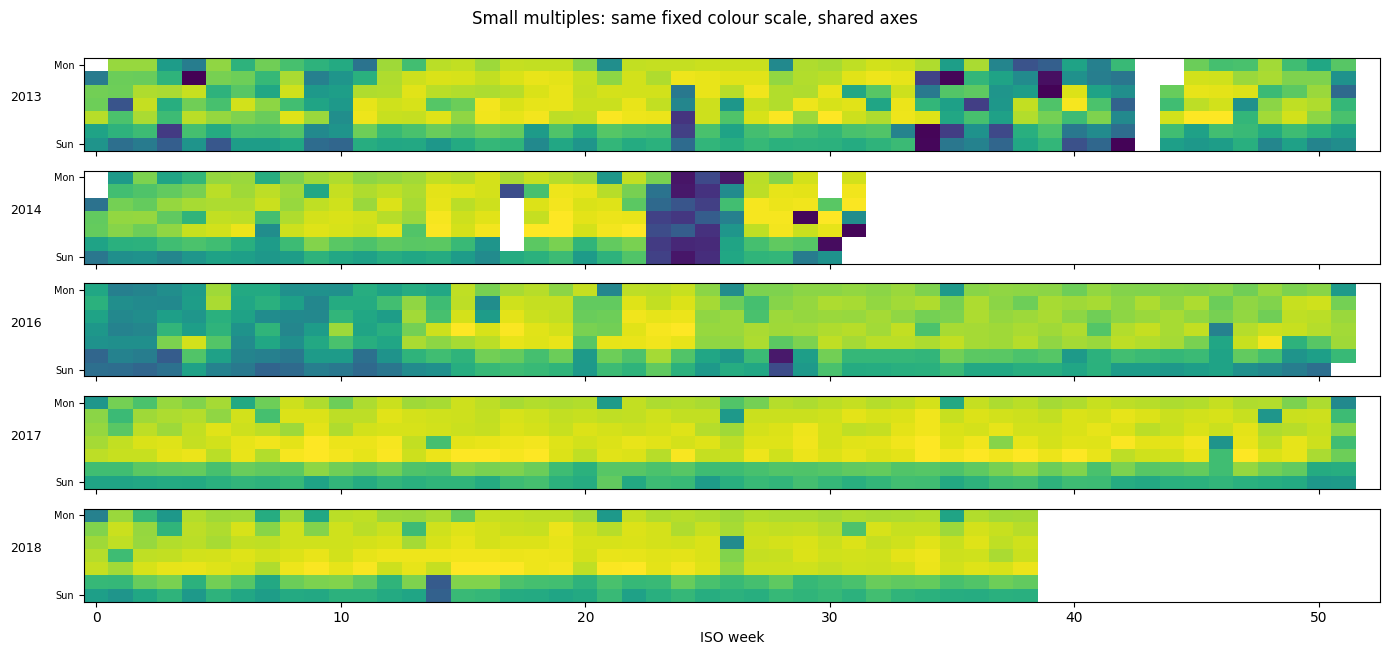

In [37]:
# The calendar animation from section 17 as small multiples: every year visible at once, so eyes compare instead of memory
fig, axs = plt.subplots(len(years), 1, figsize=(14, 1.3 * len(years)), sharex=True)
axs = np.atleast_1d(axs)
for ax, y in zip(axs, years):
    ax.imshow(mats[y].values, aspect="auto", cmap="viridis", vmin=0, vmax=cal.k_vehicles.quantile(0.99))
    ax.set_yticks([0, 6]); ax.set_yticklabels(["Mon", "Sun"], fontsize=7); ax.set_ylabel(y, rotation=0, labelpad=20, fontsize=9)
axs[-1].set_xlabel("ISO week"); plt.suptitle("Small multiples: same fixed colour scale, shared axes", y=1.0)
plt.tight_layout(); plt.show()

## 19. Cognitive issues and design guidelines  *(slides 37–38)*
| Cognitive issue | Where you saw it in this notebook | Mitigation |
|---|---|---|
| Working memory ≈ 3–4 chunks | Monthly animation (§13): comparing 12 frames | Traces or small multiples |
| Change blindness | Flicker demo (§12) | Blink comparator, difference view, highlighting |
| Motion grabs attention involuntarily | Wiggling holidays (§10) | Use motion only for temporary highlighting |
| Confusing order/direction | Connected scatter (§2), trajectories (§15) | Arrows, start/end marks, colour by time |
| Mental map breaks | Changing axes between frames | Fixed scales (§11, §14), staging (§11) |

### Design guidelines checklist
1. Decide whether time needs animation at all. **Position (x-axis) is usually best for time.**
2. Use **animated transitions** (~1 s, ease-in-out, staged) to keep context between states.
3. Use **motion sparingly**, mainly for highlighting, and avoid flicker.
4. **Sample above 2× the fastest cycle**; render at ≥ 24 fps and respect the frame budget.
5. **Aggregate or filter** to match the question and the pixels available.
6. Provide **playback, scrubbing and navigation**, and always show the current time.
7. For analysis, prefer **static views, traces or small multiples**: eyes beat memory.
8. Keep **scales, colours and layouts fixed** across frames.